# Week 3 · Decision trees

The next syllabus topic. A decision tree asks a chain of yes/no questions about the features, like *"night shift?"* then *"temperature above 72?"*, and predicts at the end of the chain. The exam staple is **picking the best split of a small table by hand**, with Gini or with information gain, so sections 2–4 do exactly that, every number shown. Section 8: build a tree from scratch. **Reading:** ISL Ch. 8.1; StatQuest "Decision and Classification Trees".

**How to use this notebook**
- Run cells one at a time with **Shift + Enter**.
- Before running an example, **guess what it prints**. The real result is written after `# →` in the comments, so you can check yourself.
- **Your turn** cells are for you. Open **Show one answer** only after a real attempt.
- If things get weird, click **Restart** at the top and run from the top again.

## Words you'll see
- **node**: One question in the tree, such as "temp ≤ 72?". The first one is the **root**.
- **leaf**: An end point with no question: it holds the prediction (the majority class, or the mean value for regression).
- **split**: A question of the form "feature $j \le t$?", which sends each sample left (yes) or right (no).
- **impurity**: How mixed the classes in a node are: 0 when every sample in it has the same class.
- **greedy**: Choosing the best split for **this** node only, without looking ahead. Trees are grown greedily.

**Run this cell first.** It loads NumPy, the picture helpers (`figures.py` in this folder) and the exercise checker.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from figures import *
import checks; checks.load(globals(), "04")      # defines check(n)

## 0. Recap first · 10 min, closed book

**Quick check:** `df.groupby("line")["temp"].transform("mean")` has how many rows: one per line, or one per row of `df`?

<details><summary>Answer</summary>

One per row of `df`: each row gets its own group's mean written back. `.mean()` without `transform` gives one row per group. [03 §6 ↗](03_pandas_methods.ipynb)

</details>

**Quick check:** Write the formula for the entropy of a distribution $p$, and say what it means in words.

<details><summary>Answer</summary>

$H(p) = -\sum_i p_i \log_2 p_i$: the average surprise, in bits. [Week 2 · 02 §5 ↗](../week2/02_map_and_entropy_in_depth.ipynb)

</details>

**Quick check:** `X_test[:, None, :] - X_train[None, :, :]` with `X_test` `(5, 3)` and `X_train` `(40, 3)` has shape ...?

<details><summary>Answer</summary>

`(5, 40, 3)`: every test point paired with every training point. [02 §7 ↗](02_knn_and_numpy_workout.ipynb)

</details>

**Quick check:** $\hat p = \sigma(z)$. For which $z$ does the threshold $t = 0.5$ put the line?

<details><summary>Answer</summary>

$z = \ln\frac{0.5}{0.5} = 0$: the boundary itself. [01 §9 ↗](01_logistic_regression_in_pictures.ipynb)

</details>

**Quick check:** `a = np.arange(12).reshape(3, 4)`. What are `a[1].shape`, `a[:, 1].shape` and `a[:, 1:2].shape`?

<details><summary>Answer</summary>

`(4,)`, `(3,)`, `(3, 1)`. A number removes an axis, and a slice keeps it. (Third time this shows up: it should be automatic by now.) [Week 2 · 03 §2 ↗](../week2/03_shapes_and_slicing.ipynb)

</details>

## 1. What a decision tree is

**A decision tree predicts by asking a chain of yes/no questions about single features. Each question splits the samples into two groups, and each end point (leaf) predicts the majority class of its training samples.**

Here's the tree you'll build by hand in this notebook. It comes from 10 factory parts: temperature, whether the part was made on the night shift, and whether it turned out defective:

🖼 **Picture.** The tree, drawn by scikit-learn. Start at the top box and answer its question: **left if true, right if false**, until you reach a box without a question (a leaf). Read the class there.

In [ ]:
fig_small_tree()

- **Root:** "night ≤ 0.5?". `night` is 0 or 1, so this asks *"day shift?"*. All 10 parts start here: 6 OK, 4 defective.
- **Left (day shift):** 5 parts, all OK. Pure, so it's a leaf: predict OK.
- **Right (night shift):** 5 parts, 1 OK and 4 defective. Ask again: "temp ≤ 72?".
- "temp ≤ 72" is true for 1 part (OK) and false for 4 parts (all defective). Both are pure, so the tree stops.
- **To predict a new part:** night shift at 75°: right (night), then right (75 > 72), so **defect**.

**What it does to the feature space.** Each question cuts along one feature, so a tree splits the plane into **rectangles** with sides parallel to the axes. More depth means more, smaller rectangles:

🖼 **Picture.** Trees of increasing depth on 200 noisy points. Depth 1 is a single cut. With no depth limit, the tree carves a rectangle around almost every point.

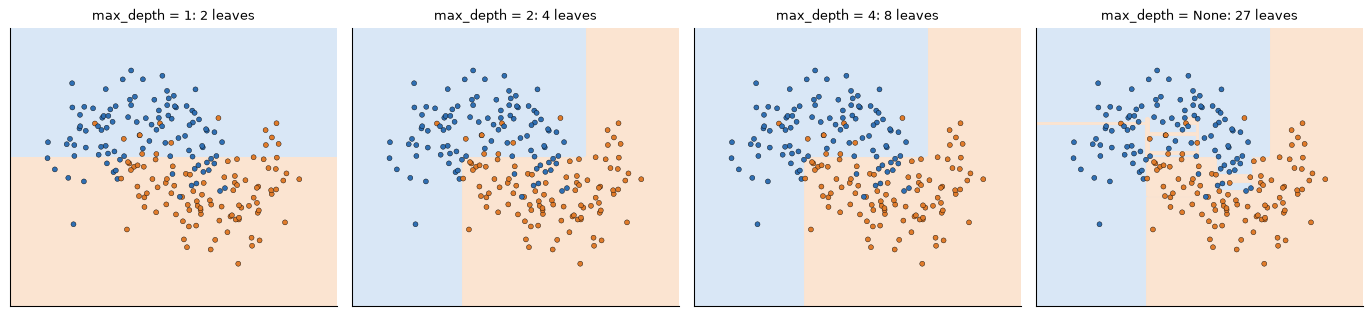

In [2]:
fig_tree_regions(depths=(1, 2, 4, None))

Compare logistic regression: one straight line at any angle ([01 §3 ↗](01_logistic_regression_in_pictures.ipynb)). A tree uses many short straight pieces, each parallel to an axis.

## 2. Impurity: Gini and entropy

**Impurity measures how mixed the classes in a node are. It's 0 when the node is pure (one class only) and largest when all classes are equally common.** The tree looks for questions whose answers make the groups purer.

**The setting.** A node holds $n$ samples. $p_k$ is the fraction of them in class $k$, so $\sum_k p_k = 1$. There are two standard impurity measures:

$$
\text{Gini}(p) = 1 - \sum_k p_k^2 \qquad\qquad H(p) = -\sum_k p_k \log_2 p_k
$$

**Where Gini comes from: the chance that two random picks disagree.** Pick a sample from the node, put it back, and pick again. Both picks are class $k$ with probability $p_k \cdot p_k$, so the two picks are the **same** class with probability $\sum_k p_k^2$. The Gini impurity is the chance that they're **different**:

$$
\text{Gini} = P(\text{two picks differ}) = 1 - \sum_k p_k^2 \;\overset{\text{2 classes}}{=}\; 1 - p^2 - (1 - p)^2 = 2p(1 - p)
$$

> ↩ **Recap** · [Your note in Week 2 · 02 §5 (entropy: reality fills both slots) ↗](../week2/02_map_and_entropy_in_depth.ipynb)
>
> You wrote $H(p) = \sum_i \underbrace{p_i}_{\text{weight}} \cdot \underbrace{(-\log p_i)}_{\text{surprise}}$: the average surprise. In a tree, it's **the average surprise at learning a sample's class, given the node it landed in.** A pure node gives 0 surprise.

**Worked example: the root of our table.** 10 parts, 4 defective ($p = 0.4$) and 6 OK:

| Measure | Calculation | Value |
|---|---|---|
| Gini | $1 - 0.4^2 - 0.6^2 = 1 - 0.16 - 0.36$ | 0.480 |
| Gini, 2-class shortcut | $2 \times 0.4 \times 0.6$ | 0.480 |
| entropy | $-0.4 \log_2 0.4 - 0.6 \log_2 0.6 = 0.4 \times 1.322 + 0.6 \times 0.737$ | 0.971 bits |
| a pure node ($p = 1$) | $1 - 1^2$ and $-1 \log_2 1$ | 0 and 0 |
| 50/50 ($p = 0.5$) | $2 \times 0.5 \times 0.5$ and $-2 \times 0.5 \log_2 0.5$ | 0.5 and 1 bit (the maximum) |

🖼 **Picture.** Both curves are 0 at the ends and peak at 50/50. Entropy is a bit more "rounded"; in practice the two almost always choose the same split.

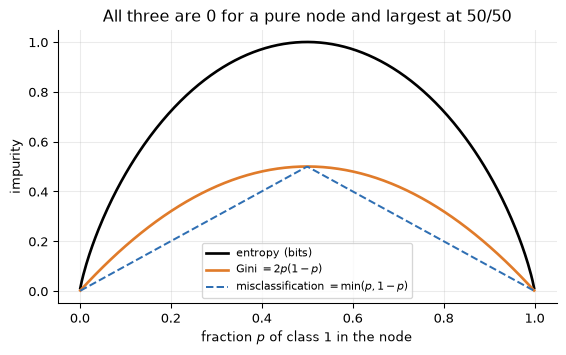

In [3]:
fig_impurity_curves()

| Property | Gini | Entropy |
|---|---|---|
| pure node | 0 | 0 |
| maximum (2 classes) | 0.5 at 50/50 | 1 bit at 50/50 |
| maximum ($K$ classes) | $1 - \frac{1}{K}$ | $\log_2 K$ |
| cost | squares only: fast | needs logs |
| scikit-learn | `criterion="gini"` (default) | `criterion="entropy"` |

In [4]:
def gini(y):
    p = np.bincount(y) / len(y)
    return 1 - np.sum(p ** 2)

def entropy(y):
    p = np.bincount(y) / len(y); p = p[p > 0]     # skip empty classes: 0·log 0 counts as 0
    return -np.sum(p * np.log2(p))

y = np.array([0, 0, 0, 0, 1, 0, 1, 1, 0, 1])           # our 10 parts
print(round(gini(y), 3), round(entropy(y), 3))         # → 0.48 0.971

0.48 0.971


## 3. Choosing a split

**The best split is the one that lowers impurity the most: the parent's impurity minus the weighted average impurity of the two children.** With entropy, this decrease is called **information gain**.

$$
\Delta = I(\text{parent}) - \Big(\frac{n_L}{n}\, I(L) + \frac{n_R}{n}\, I(R)\Big)
$$

$I$ is the impurity (Gini or entropy), $L$ and $R$ are the two children, and $n_L + n_R = n$. The children are **weighted by their size**, so a tiny pure child doesn't count for much. In words, information gain is how much surprise the question removes on average.

**The table.** Which first question separates the defective parts best?

| Part | temp | night | defect |
|---|---|---|---|
| 1 | 68 | 0 | 0 |
| 2 | 70 | 0 | 0 |
| 3 | 71 | 1 | 0 |
| 4 | 72 | 0 | 0 |
| 5 | 73 | 1 | 1 |
| 6 | 74 | 0 | 0 |
| 7 | 75 | 1 | 1 |
| 8 | 77 | 1 | 1 |
| 9 | 78 | 0 | 0 |
| 10 | 80 | 1 | 1 |

**Candidate 1: "night shift?"** Night parts are 3, 5, 7, 8, 10, with defects 0, 1, 1, 1, 1: 4 out of 5. Day parts are 1, 2, 4, 6, 9: all OK.

|  | Count | $p$(defect) | Gini | Entropy |
|---|---|---|---|---|
| parent | 10 | 0.4 | 0.480 | 0.971 |
| night = yes | 5 | 0.8 | $2(0.8)(0.2) = 0.320$ | 0.722 |
| night = no | 5 | 0 | 0 | 0 |
| weighted children |  |  | $0.5(0.32) + 0.5(0) = 0.160$ | $0.5(0.722) = 0.361$ |
| **decrease** |  |  | $0.480 - 0.160 = \mathbf{0.320}$ | $0.971 - 0.361 = \mathbf{0.610}$ bits |

**Candidate 2: "temp ≤ $t$?"** For a numeric feature, sort the values and try a threshold **halfway between each pair of neighbours**: 69, 70.5, 71.5, ..., 79. Any other threshold puts the same parts on each side as one of these, so nothing is lost. Nine candidates:

| Threshold | Left (temp ≤ t) | Right | Gini left | Gini right | Weighted | Decrease |
|---|---|---|---|---|---|---|
| 69 | 0 | 0 0 0 1 0 1 1 0 1 | 0 | 0.494 | 0.444 | 0.036 |
| 70.5 | 0 0 | 0 0 1 0 1 1 0 1 | 0 | 0.500 | 0.400 | 0.080 |
| 71.5 | 0 0 0 | 0 1 0 1 1 0 1 | 0 | 0.490 | 0.343 | 0.137 |
| **72.5** | 0 0 0 0 | 1 0 1 1 0 1 | 0 | 0.444 | **0.267** | **0.213** |
| 73.5 | 0 0 0 0 1 | 0 1 1 0 1 | 0.320 | 0.480 | 0.400 | 0.080 |
| 74.5 | 0 0 0 0 1 0 | 1 1 0 1 | 0.278 | 0.375 | 0.317 | 0.163 |
| 76 | 0 0 0 0 1 0 1 | 1 0 1 | 0.408 | 0.444 | 0.419 | 0.061 |
| 77.5 | 0 0 0 0 1 0 1 1 | 0 1 | 0.469 | 0.500 | 0.475 | 0.005 |
| 79 | 0 0 0 0 1 0 1 1 0 | 1 | 0.444 | 0 | 0.400 | 0.080 |

**The 72.5 row, by hand**

- Left: parts 1–4, all OK, so Gini $= 0$.
- Right: parts 5–10, with 4 defective out of 6, so $p = \frac{2}{3}$ and Gini $= 2 \cdot \frac{2}{3} \cdot \frac{1}{3} = 0.444$.
- Weighted: $\frac{4}{10} \times 0 + \frac{6}{10} \times 0.444 = 0.267$.
- Decrease: $0.480 - 0.267 = 0.213$.

🖼 **Picture.** Top: the parts along the temperature axis (orange = defective) and every candidate threshold. Bottom: the weighted Gini for each; the lowest is at 72.5.

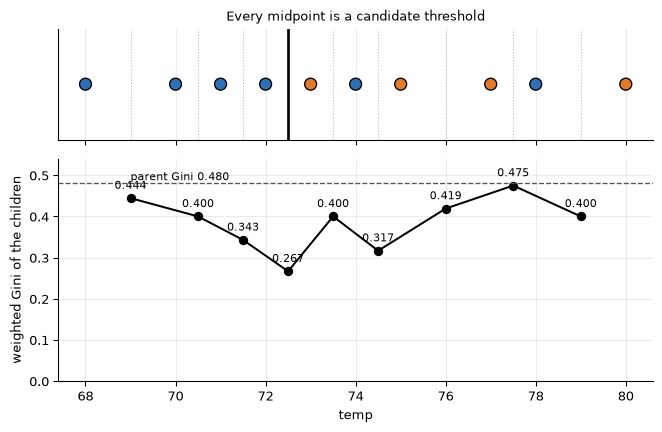

In [5]:
fig_split_scan([68, 70, 71, 72, 73, 74, 75, 77, 78, 80], [0, 0, 0, 0, 1, 0, 1, 1, 0, 1], name="temp")

**The winner.** The best temperature split lowers Gini by 0.213; "night shift?" lowers it by **0.320**. So the root question is **night shift?** Entropy agrees: night gives 0.610 bits and the best temperature split gives 0.420.

**Drill (on paper).** Same table. Compute the information gain (entropy) of the split "temp ≤ 72.5".

<details><summary>Worked answer</summary>

Left: 4 parts, all OK, $H = 0$. Right: 6 parts, 4 defective: $H = -\frac{2}{3}\log_2\frac{2}{3} - \frac{1}{3}\log_2\frac{1}{3} = 0.390 + 0.528 = 0.918$. Weighted: $0.6 \times 0.918 = 0.551$. Gain: $0.971 - 0.551 = 0.420$ bits, less than night's 0.610.

</details>

## 4. Growing the tree: recursive and greedy

**CART (the standard tree algorithm) picks the best split for the current node, divides the data, and then does the same thing again inside each child, until a stopping rule says "make this a leaf".**

```text
grow(X, y, depth):                                   pseudocode, close to real Python
    if depth == max_depth  or  all labels in y are equal  or  no split lowers the impurity:
        return a leaf: the majority class of y
    j, t = the (feature, threshold) with the biggest impurity decrease
    left = rows with X[:, j] <= t
    return a node (j, t) with children  grow(X[left], y[left], depth + 1)
                                   and  grow(X[~left], y[~left], depth + 1)
```

**The second split, by hand.** The "no" side of the root (day shift) is already pure, so it becomes a leaf: OK. The "yes" side holds parts 3, 5, 7, 8, 10 with temperatures 71, 73, 75, 77, 80 and labels 0, 1, 1, 1, 1. Night is the same for all of them, so only temperature can split. Its candidates are 72, 74, 76, 78.5:

| Threshold | Left | Right | Weighted Gini | Decrease (from 0.320) |
|---|---|---|---|---|
| **72** | 0 | 1 1 1 1 | **0** | **0.320** |
| 74 | 0 1 | 1 1 1 | $\frac{2}{5}(0.5) = 0.200$ | 0.120 |
| 76 | 0 1 1 | 1 1 | $\frac{3}{5}(0.444) = 0.267$ | 0.053 |
| 78.5 | 0 1 1 1 | 1 | $\frac{4}{5}(0.375) = 0.300$ | 0.020 |

"temp ≤ 72" makes both children pure, so the tree stops: it's the tree drawn in section 1. **Read it out loud: defects happen on the night shift when the temperature is above 72.** That kind of readable rule is why factories like trees.

In [6]:
from sklearn.tree import DecisionTreeClassifier, export_text
X = np.column_stack([[68, 70, 71, 72, 73, 74, 75, 77, 78, 80], [0, 0, 1, 0, 1, 0, 1, 1, 0, 1]])
tree = DecisionTreeClassifier(max_depth=2).fit(X, y)
print(export_text(tree, feature_names=["temp", "night"]))
# → |--- night <= 0.50
#   |   |--- class: 0
#   |--- night >  0.50
#   |   |--- temp <= 72.00
#   |   |   |--- class: 0
#   |   |--- temp >  72.00
#   |   |   |--- class: 1

|--- night <= 0.50
|   |--- class: 0
|--- night >  0.50
|   |--- temp <= 72.00
|   |   |--- class: 0
|   |--- temp >  72.00
|   |   |--- class: 1



scikit-learn found the same tree. **Greedy** means each split is the best one *for that node*, with no look-ahead. A split that looks useless now but would enable a great split later is never chosen. That's a known weakness, and it's accepted because searching all trees is far too slow.

## 5. Regression trees

**For a numeric target, a leaf predicts the mean of its samples, and the best split is the one that lowers the sum of squared errors (SSE) the most.**

$$
\text{SSE}(\text{split}) = \sum_{i \in L} (y_i - \bar y_L)^2 + \sum_{i \in R} (y_i - \bar y_R)^2
$$

$\bar y_L$ and $\bar y_R$ are the means of the two children. It's the same recipe as classification, with SSE playing the role of impurity: it's 0 when every value in the node is equal. **Worked example:** $x = (1, 2, 3, 4, 5, 6)$ and $y = (5, 6, 5, 12, 13, 14)$. Before any split, the mean is 9.17 and the SSE is 90.83.

| Threshold | Left mean | Right mean | SSE left | SSE right | Total SSE |
|---|---|---|---|---|---|
| 1.5 | 5.00 | 10.00 | 0 | 70.0 | 70.0 |
| 2.5 | 5.50 | 11.00 | 0.5 | 50.0 | 50.5 |
| **3.5** | **5.33** | **13.00** | 0.67 | 2.0 | **2.67** |
| 4.5 | 7.00 | 13.50 | 34.0 | 0.5 | 34.5 |
| 5.5 | 8.20 | 14.00 | 62.8 | 0 | 62.8 |

The 3.5 row by hand: the left values are $5, 6, 5$ with mean $5.33$, so the squared deviations are $0.11 + 0.44 + 0.11 = 0.67$. The right values are $12, 13, 14$ with mean $13$, giving $1 + 0 + 1 = 2$. So the tree predicts **5.33 for $x \le 3.5$ and 13 for $x > 3.5$**: a step function.

🖼 **Picture.** Regression trees on a noisy sine wave. Each leaf is a flat step; more depth means more steps, and eventually it follows the noise.

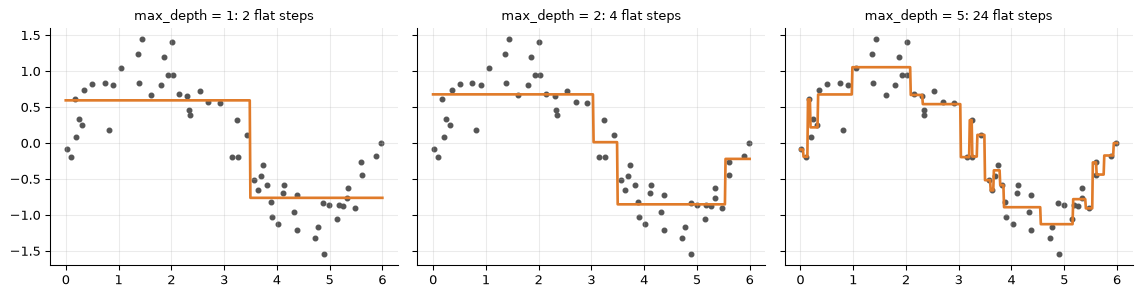

In [7]:
fig_regression_tree(depths=(1, 2, 5))

## 6. Overfitting, and how to stop it

**A tree that keeps splitting will eventually put every training sample in its own leaf: 100% training accuracy, and poor test accuracy. You stop it by limiting its growth, or by growing it fully and then pruning it back.**

🖼 **Picture.** Training accuracy climbs to 1.0 as the depth grows; test accuracy peaks early and then drops. That's the bias–variance trade-off of [Week 1 · math §8 ↗](../week1/03_math_essentials.ipynb).

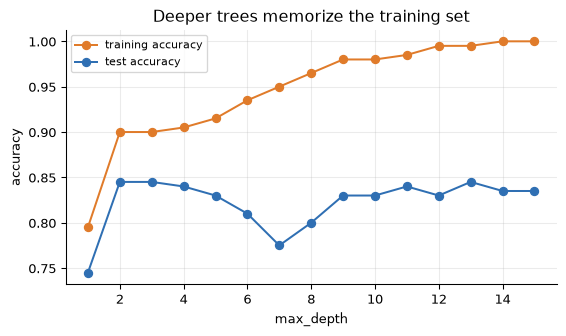

In [8]:
fig_depth_curve()

| Setting (scikit-learn) | Effect |
|---|---|
| `max_depth` | at most this many questions on any path |
| `min_samples_leaf` | every leaf keeps at least this many samples (no single-point leaves) |
| `min_samples_split` | a node needs at least this many samples to be split |
| `ccp_alpha` | cost-complexity pruning (below) |

**Cost-complexity pruning.** Grow the full tree, then trade training error against size with one knob $\alpha \ge 0$:

$$
R_\alpha(T) = \underbrace{R(T)}_{\text{training error of tree } T} + \alpha \underbrace{\lvert T \rvert}_{\text{number of leaves}}
$$

Each leaf now costs $\alpha$. **Worked example:** a branch with 3 leaves has training error 0.05. Cutting it back to a single leaf raises the error to 0.15. Keep the branch if $0.05 + 3\alpha < 0.15 + 1\alpha$, i.e. if $\alpha < 0.05$. So **for any $\alpha$ above 0.05 the branch is pruned.** A bigger $\alpha$ gives a smaller tree; choose $\alpha$ by cross-validation.

**Properties of trees.** No scaling needed (a split only compares values within one feature). Mixed feature types are fine. Easy to read. But they're **unstable**: change a few training points and the root split can change, and the whole tree with it. That high variance is exactly what ensembles (notebook `06`) fix.

## 7. Trees in scikit-learn

**Feature importance** adds up how much each feature lowered the impurity over the whole tree, weighting each node by its sample count, and then normalizes the totals so they sum to 1. In our tree: the root lowers $10 \times 0.48 - 5 \times 0.32 = 3.2$ (night) and the second split lowers $5 \times 0.32 = 1.6$ (temp), so the importances are $\frac{3.2}{4.8} = 0.667$ for night and $\frac{1.6}{4.8} = 0.333$ for temp.

In [9]:
print(tree.feature_importances_.round(3))      # → [0.333 0.667]   [temp, night]

[0.333 0.667]


On real data, choose the depth with cross-validation. Trees need no scaler, so there's no pipeline here:

In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import GridSearchCV, train_test_split
Xb, yb = load_breast_cancer(return_X_y=True)
Xa, Xt, ya, yt = train_test_split(Xb, yb, test_size=0.25, random_state=0, stratify=yb)
search = GridSearchCV(DecisionTreeClassifier(random_state=0), {"max_depth": [1, 2, 3, 4, 5, 8, None]}, cv=5)
search.fit(Xa, ya)
print(search.best_params_, round(search.best_score_, 3))     # → {'max_depth': 5} 0.93
print(round(search.score(Xt, yt), 3))                        # → 0.902   test accuracy of the chosen tree

{'max_depth': 5} 0.93
0.902


`GridSearchCV` runs 5-fold CV for every setting in the grid, keeps the best, and refits it on all the training data. It's the loop you wrote for $k$ in [Week 2 · 06 §4 ↗](../week2/06_pandas_and_sklearn.ipynb), done for you. Logistic regression scored 0.958 on the same split ([Week 2 · 06 §3 ↗](../week2/06_pandas_and_sklearn.ipynb)): one tree is decent, not great. Ensembles close that gap (notebook `06`).

## 8. Build it yourself

Seven pieces that make a complete tree. Labels are whole numbers 0, 1, 2, ... (so `np.bincount` works). A tree is stored as nested dictionaries:

```text
leaf:   {"leaf": 1}
node:   {"feature": 1, "threshold": 0.5,
         "left":  <tree for rows with x[1] <= 0.5>,
         "right": <tree for the other rows>}
```

✏️ **Exercise 1 · Gini impurity.** $1 - \sum_k p_k^2$ for an array of labels. Use `np.bincount(y) / len(y)` for the $p_k$. Return 0.0 for an empty array.

In [11]:
def gini(y):
    pass  # your code

In [12]:
check(1)

Exercise 1: something returned None. Not written yet, or a missing `return`?


✏️ **Exercise 2 · Entropy.** $-\sum_k p_k \log_2 p_k$ in bits, skipping classes with $p_k = 0$. Return 0.0 for an empty array.

In [13]:
def entropy(y):
    pass  # your code

In [14]:
check(2)

Exercise 2: something returned None. Not written yet, or a missing `return`?


✏️ **Exercise 3 · Gain of a split.** `mask` is a True/False array (True = goes left). Return $I(y) - \frac{n_L}{n} I(y_L) - \frac{n_R}{n} I(y_R)$, where `impurity` is a **function you're given** (`gini` or `entropy`): call it as `impurity(y)`. Functions can be passed around like any other value.

In [15]:
def split_gain(y, mask, impurity):
    pass  # your code

In [16]:
check(3)

Exercise 3: something returned None. Not written yet, or a missing `return`?


✏️ **Exercise 4 · Best threshold on one feature.** Try every midpoint between consecutive **unique** values of `x` (`np.unique` sorts them). Return `(threshold, gain)` for the threshold with the largest Gini gain; for ties, keep the smallest threshold. If `x` has only one distinct value, return `(None, 0.0)`.

In [17]:
def best_threshold(x, y):
    pass  # your code

In [18]:
check(4)

Exercise 4: something returned None. Not written yet, or a missing `return`?


✏️ **Exercise 5 · Best split over all features.** Return `(feature, threshold, gain)`: the best of `best_threshold` over the columns of `X`. For ties, keep the lower feature index.

In [19]:
def best_split(X, y):
    pass  # your code

In [20]:
check(5)

Exercise 5: something returned None. Not written yet, or a missing `return`?


✏️ **Exercise 6 · Build the tree.** Recursive. Return a leaf (majority label: `int(np.bincount(y).argmax())`) if `max_depth == 0`, or `y` is pure, or the best gain is not above 0. Otherwise split with `best_split` and build both children with `max_depth - 1`. The checker builds the tree from section 4 and expects the same answer: night first, then temp ≤ 72.

In [21]:
def build_tree(X, y, max_depth):
    pass  # your code

In [22]:
check(6)

Exercise 6: something returned None. Not written yet, or a missing `return`?


✏️ **Exercise 7 · Predict.** For each row of `X`, start at the root and go left if `x[feature] <= threshold`, otherwise right, until you reach a leaf. Return the labels as an array, shape `(n,)`.

In [23]:
def predict_tree(tree, X):
    pass  # your code

In [24]:
check(7)

Exercise 7: not right yet. A test case gives the wrong answer (re-read the description and try the edge cases)


In [25]:
for n in range(1, 8):
    check(n)

Exercise 1: something returned None. Not written yet, or a missing `return`?
Exercise 2: something returned None. Not written yet, or a missing `return`?
Exercise 3: something returned None. Not written yet, or a missing `return`?
Exercise 4: something returned None. Not written yet, or a missing `return`?
Exercise 5: something returned None. Not written yet, or a missing `return`?
Exercise 6: something returned None. Not written yet, or a missing `return`?
Exercise 7: not right yet. A test case gives the wrong answer (re-read the description and try the edge cases)


---
Solutions: `solutions/04_solutions.py`. Next: `05_svm.ipynb`.